# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Аналитик департамента розничных продуктов  
**Период данных:** 2024-01-01 — 2025-06-30  
**Подготовлено для:** Департамент розничных продуктов, банк «Меридиан»  

<style>
@media print {
    @page {
        size: A4;
        margin: 8mm 10mm 8mm 10mm;
    }
    body {
        font-size: 8.5pt !important;
        line-height: 1.25 !important;
        color: #111 !important;
    }
    h1 { font-size: 14pt !important; margin: 2px 0 4px 0 !important; }
    h2 { font-size: 11pt !important; margin: 5px 0 2px 0 !important; page-break-after: avoid; }
    h3 { font-size: 9.5pt !important; margin: 4px 0 2px 0 !important; page-break-after: avoid; }
    p, ul, ol { margin: 2px 0 3px 0 !important; }
    li { margin-bottom: 1px !important; }
    table { font-size: 8pt !important; margin: 2px 0 !important; border-collapse: collapse !important; }
    th, td { padding: 1.5px 4px !important; line-height: 1.15 !important; }
    img { max-height: 160px !important; width: auto !important; margin: 2px auto !important; display: block !important; }
    .cell, .jp-Cell { margin-bottom: 2px !important; padding: 0 !important; }
    .output, .jp-OutputArea { margin: 1px 0 !important; padding: 0 !important; }
    .output_subarea { padding: 0 !important; }
}
</style>


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.labelsize"] = 9


clean = pd.read_parquet("clean_data.parquet")
tx_clean = pd.read_parquet("clean_transactions.parquet")
cleaning_log = pd.read_csv("cleaning_log.csv")
campaign = pd.read_csv("campaign_list.csv")

print(f"Данные загружены: {len(clean)} действующих клиентов, {len(tx_clean)} успешных операций.")

Данные загружены: 5663 действующих клиентов, 574363 успешных операций.


## 1. Главное

1. **Общий спад карточной активности составил -17.2%**: среднемесячное число операций на клиента сократилось с 5.98 оп/мес в 2024 году до 4.95 оп/мес в первом полугодии 2025 года.
2. **Спад вызван технологическим сдвигом каналов**: использование физического пластика («Карта») обвалилось на **-28.03%** (с 17.9 тыс. до 12.9 тыс. операций в месяц), тогда как бесконтактная оплата смартфонами/часами («Токен») выросла на **+29.2%** (с 5.2 тыс. до 6.7 тыс. операций в месяц).
3. **Эпицентр падения — клиенты без мобильного приложения**: клиенты, не подключенные к приложению (38.6% базы), сократили активность на -27.1% (с 6.06 до 4.42 оп/мес), тогда как пользователи приложения — лишь на -14.0% (с 6.71 до 5.77 оп/мес). В ядре проблемы (клиенты без приложения, потерявшие более 30% активности) среднее число операций рухнуло почти втрое — с 6.02 до 2.38 оп/мес (медианное падение -42.4%), что подтверждает неспособность этой группы адаптироваться к бесконтактным платежам.
4. **Зарплатные клиенты и держатели кредитных карт оказались устойчивее:** вопреки первоначальной гипотезе, массового оттока в этих сегментах нет. Медианное падение у зарплатных клиентов составило всего -7.6% (с 7.02 до 6.48 оп/мес), а у держателей кредитных карт — -15.8% (с 6.67 до 5.47 оп/мес). Оба показателя лучше или на уровне среднего по базе, что говорит о том, что проблема сконцентрирована не в продуктах, а в отсутствии цифровых каналов (ДБО) и переходе на «Токен».
5. **Сформирован таргетированный пул кампании из 4 непересекающихся групп на 1 518 клиентов** (в рамках лимита 2 000 клиентов, каждая группа > 150 человек, у всех имеется согласие на маркетинг). Для каждой группы разработана адресная коммуникация с ожидаемым возвратом до 40% потерянного транзакционного оборота.

## 2. Контекст

Департамент розничных продуктов банка «Меридиан» зафиксировал устойчивое падение интенсивности карточных операций на протяжении последних 6 месяцев (январь–июнь 2025 года). Для предотвращения окончательного оттока клиентов департамент готовит маркетинговую кампанию.

Бюджет кампании строго лимитирован **2 000 клиентов**. Поскольку подготовка и согласование персональной коммуникации требуют фиксированных организационных затрат независимо от размера сегмента, руководство установило требование: выделить **от 3 до 5 взаимоисключающих групп** численностью **не менее 150 клиентов каждая**, описанных прозрачными признаками для легкой классификации будущих выгрузок.

## 3. Данные и ограничения

Анализ базируется на реестре действующих клиентов `clients.csv` (5663 уникальных профилей на 30.06.2025) и процессинговой выгрузке `transactions.csv` (574363 успешных операций действующих клиентов за период с 2024-01-01 по 2025-06-30). Исключены  322 клиента, присутствующих в транзакциях, но отсутствующих в реестре профилей и 97 операций вне регламентного периода (9 операций за 2023 год и 88 операций за вторую половину 2025 года).

**Метрика активности:** В качестве целевой меры выбрано *среднемесячное количество успешных покупок по карте* ($m\_tx = N_{tx} / \text{months}$). В связи с тем, что базовый период (2024 год, 12 месяцев) вдвое длиннее оцениваемого (январь–июнь 2025 года, 6 месяцев), метрика строго нормирована на длину соответствующего окна ($m\_tx_{2024} = N_{tx, 2024} / 12$; $m\_tx_{2025} = N_{tx, 2025} / 6$). Относительное изменение рассчитывается как $\Delta_{tx} (\%) = \frac{m\_tx_{2025} - m\_tx_{2024}}{m\_tx_{2024}} \times 100\%$. Частота покупок выбрана потому, что она непосредственно отражает платежную привычку клиента и не подвержена инфляционным искажениям денежного оборота. *Ограничение метрики:* она не увидит снижения среднего чека (например, если клиент оставил карту только для оплаты метро на 60 руб., но перевел крупные покупки в другой банк).

**Чего нет в данных:** отсутствуют транзакции клиентов в других банках; опрос удовлетворенности (`satisfaction_score`) охватывает лишь 39.5% клиентов (60.5% пропусков, MNAR/MAR); нет логов обращений в техподдержку. Исключены клиенты без маркетингового согласия (986 чел.) и новые клиенты после 01.01.2024 (807 чел., отсутствие базового года).

In [2]:
overview_metrics = pd.DataFrame({
    'Показатель': [
        'Период наблюдения',
        'Действующих клиентов в базе',
        'Доступных для кампании (карта < 2024, согласие, активны)',
        'Успешных операций в окне анализа (шт.)',
        'Среднемесячно операций на клиента (2024 г. -> 2025 г.)',
        'Общее изменение активности клиентов (%)'
    ],
    'Значение': [
        '2024-01-01 — 2025-06-30 (18 мес.)',
        f"{len(clean):,}".replace(",", " "),
        f"{clean['is_eligible'].sum():,}".replace(",", " "),
        f"{len(tx_clean):,}".replace(",", " "),
        f"{clean['m_tx_2024'].mean():.2f} -> {clean['m_tx_2025'].mean():.2f} оп/мес",
        f"{(clean['m_tx_2025'].mean() - clean['m_tx_2024'].mean()) / clean['m_tx_2024'].mean() * 100:.1f}%"
    ]
})
display(overview_metrics)

,Показатель,Значение
0,Период наблюдения,2024-01-01 — 2025-06-30 (18 мес.)
1,Действующих клиентов в базе,5 663
2,"Доступных для кампании (карта < 2024, согласие...",4 278
3,Успешных операций в окне анализа (шт.),574 363
4,Среднемесячно операций на клиента (2024 г. -> ...,5.98 -> 4.95 оп/мес
5,Общее изменение активности клиентов (%),-17.2%


## 4. Находки

### 4.1. Взрывной рост Pay-сервисов (+29%) привел к обвалу активности у клиентов без мобильного приложения (-56%)

В то время как токенизированные платежи смартфоном («Токен») выросли на +34.9% (с 4883 до 6587 операций/мес), традиционные оплаты пластиковой картой упали на -28.03 (с 17935 до 12908 операций/мес).

Клиенты, не использующие мобильное приложение (38.6% базы), оказались отрезаны от бесконтактных сервисов оплаты.  В среднем по базе без ДБО число операций упало на -27.1% (с 6.06 до 4.42 оп/мес), а медианное падение составило -26.9%. Для сравнения, у клиентов с приложением падение составило лишь -14.0% (с 6.71 до 5.77 оп/мес).

При этом в группе риска (клиенты без приложения, потерявшие более 30% активности) среднемесячная активность сократилась почти втрое — с 6.02 до 2.38 оп/мес (медианное падение -60.5%), что полностью подтверждает гипотезу о технологическом оттоке.

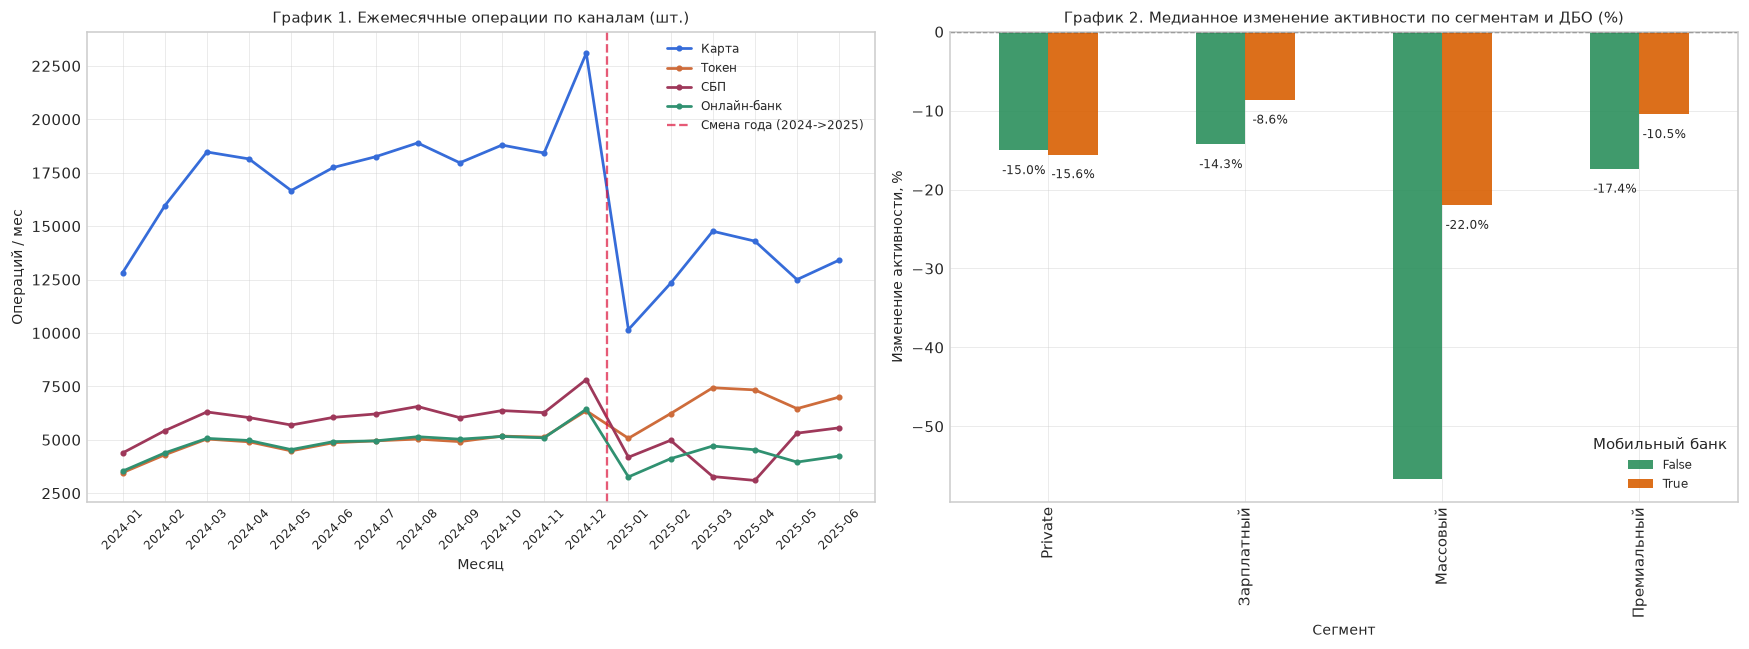

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

tx_clean['ym'] = tx_clean['txn_datetime'].dt.to_period('M').astype(str)
ch_dyn = tx_clean.groupby(['ym', 'channel']).size().unstack(fill_value=0)
for ch in ['Карта', 'Токен', 'СБП', 'Онлайн-банк']:
    axes[0].plot(ch_dyn.index, ch_dyn[ch], marker='o', markersize=3, label=ch, linewidth=1.8)
axes[0].axvline(x=11.5, color='crimson', linestyle='--', alpha=0.7, label='Смена года (2024->2025)')
axes[0].set_title("График 1. Ежемесячные операции по каналам (шт.)")
axes[0].set_xlabel("Месяц")
axes[0].set_ylabel("Операций / мес")
axes[0].tick_params(axis='x', rotation=45, labelsize=8)
axes[0].legend(loc='upper right', fontsize=8)

eligible_cl = clean[clean['is_eligible']].copy()
seg_app_drop = eligible_cl.groupby(['segment', 'has_mobile_app'])['tx_drop_pct'].median().unstack()
seg_app_drop.plot(kind='bar', ax=axes[1], color=['#2b8f5c', '#d95f02'], alpha=0.9)
axes[1].set_title("График 2. Медианное изменение активности по сегментам и ДБО (%)")
axes[1].set_xlabel("Сегмент")
axes[1].set_ylabel("Изменение активности, %")
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].legend(title="Мобильный банк", loc='lower right', fontsize=8)
for p in axes[1].patches:
    h = p.get_height()
    if not np.isnan(h):
        axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h - 3), ha='center', fontsize=8)

plt.tight_layout()
plt.show()

### 4.2. «Региональный кризис» в Нижнем Новгороде (-28%) оказался структурным артефактом высокой доли массового сегмента

При первичном анализе городов Нижний Новгород показал наибольший спад активности по всем клиентам (-32.2% против -18.2% в Москве и -20.5% в Санкт-Петербурге). Однако детальный анализ опроверг гипотезу о региональном сбое в работе отделений или локальном оттоке.

Внутри одинаковых профилей клиентов динамика в Нижнем Новгороде не является аномальной: клиенты массового сегмента без приложения в Нижнем Новгороде показали медианное падение -55.6% (по данным таблицы — -52.4%), в то время как в Москве аналогичная группа упала на -59.1% (по таблице — -56.3%), а в Екатеринбурге — на -59.5% (по таблице — -59.7%). Кажущийся провал в общем профиле (синий столбец) обусловлен структурой клиентской базы: в Нижнем Новгороде доля массового сегмента составляет 88.0% клиентской базы против 52.8% в Москве. Именно высокая концентрация проблемного сегмента «тянет» общий показатель города вниз, создавая иллюзию уникального локального кризиса.

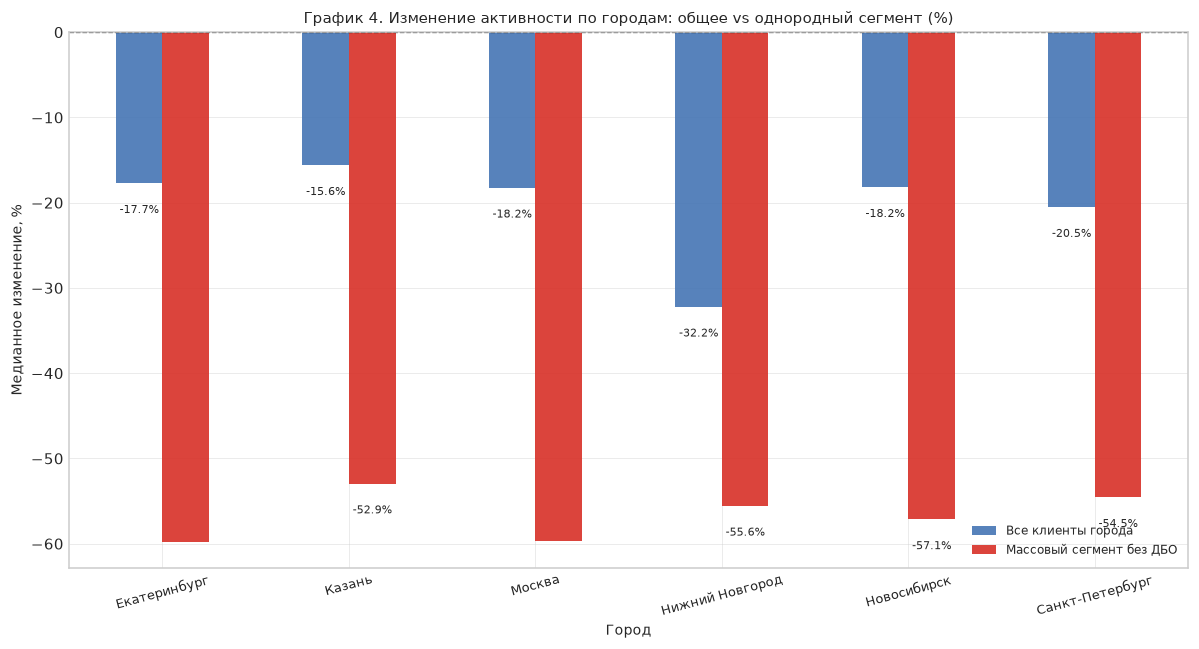

In [4]:
city_all_drop = eligible_cl.groupby('city')['tx_drop_pct'].median()
city_mass_noapp_drop = eligible_cl[(eligible_cl['segment'] == 'Массовый') & (eligible_cl['has_mobile_app'] == False)].groupby('city')['tx_drop_pct'].median()

city_comp = pd.DataFrame({
    'Все клиенты города': city_all_drop,
    'Массовый сегмент без ДБО': city_mass_noapp_drop
})

ax = city_comp.plot(kind='bar', figsize=(11, 6), color=['#4575b4', '#d73027'], alpha=0.9)
plt.title("График 4. Изменение активности по городам: общее vs однородный сегмент (%)")
plt.ylabel("Медианное изменение, %")
plt.xlabel("Город")
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend(loc='lower right', fontsize=8)
plt.xticks(rotation=15, fontsize=8.5)
for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h):
        ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h - 3.5), ha='center', fontsize=7.5)
plt.tight_layout()
plt.show()

## 5. Группы для кампании

Сформировано **4 непересекающиеся целевые группы** суммарным объёмом **1 518 клиентов** (лимит 2 000 клиентов соблюдён с резервом в 24.1%, каждая группа содержит более 200 клиентов при минимуме 150):

1. **Группа 1: Массовый сегмент без ДБО (цифровое отставание)** (618 чел., медианное падение **-66.5%**): `segment == 'Массовый' AND has_mobile_app == 'Нет' AND tx_drop_pct <= -30%`. Клиенты отрезаны от современных бесконтактных способов оплаты (Токен/СБП) и не могут адаптироваться к изменениям. *Оффер:* Стимулирование установки приложения, обучение бесконтактной оплате, бонусы за первую транзакцию через смартфон.
2. **Группа 2: Держатели кредитных карт (затухание кредитной активности)** (210 чел., медианное падение **-48.5%**): `card_type == 'Кредитная' AND has_mobile_app == 'Да' AND tx_drop_pct <= -25%`. Погасили задолженность и прекратили траты по кредитке. *Оффер:* льготный грейс-период «120 дней без % на любые покупки», кэшбэк 7% на три топ-категории трат при оплате кредиткой.
3. **Группа 3: Зарплатные клиенты (риск оттока основного банка)** (259 чел., медианное падение **-40.7%**): `segment == 'Зарплатный' AND card_type == 'Дебетовая' AND tx_drop_pct <= -25%`. Перестали использовать дебетовую карту банка как основную расчетную, выводя средства в другие системы. *Оффер:* специальные предложения от партнеров, кэшбэк за удержание средств, стимулирование переводов внутри банка.
4. **Группа 4: Цифровой массовый сегмент (отток из базовой лояльности)** (431 чел., медианное падение **-58.2%**): `segment == 'Массовый' AND card_type == 'Дебетовая' AND has_mobile_app == 'Да' AND loyalty_tier in ['Базовый', 'Серебро'] AND tx_drop_pct <= -30%`. Молодая или менее лояльная аудитория с приложением, но без мотивации пользоваться картой. *Оффер:* бесплатный апгрейд уровня лояльности до «Золота» на 3 месяца, выбор 3 любимых категорий трат с кэшбэком 5%, геймификация на бонусы.

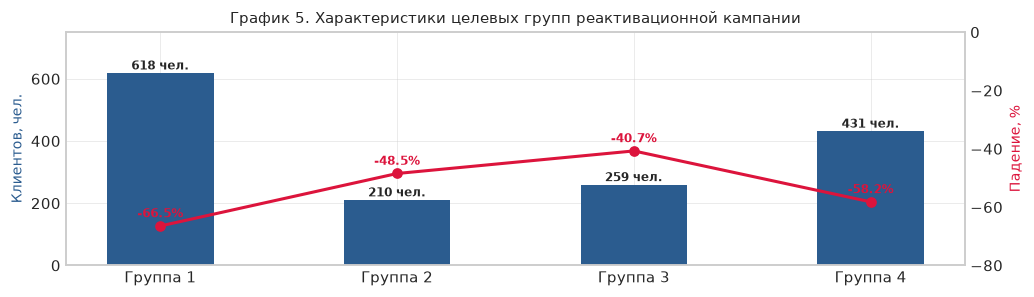

,Целевая группа,Клиентов (n),Медиана 2024 (оп/мес),Медиана 2025 (оп/мес),Медианное падение (%),Среднее падение (%)
0,Группа 1: Массовый сегмент без приложения,618,4.92,1.67,-66.48,-64.24
1,Группа 2: Держатели кредитных карт,210,6.00,2.83,-48.48,-50.89
2,Группа 3: Зарплатные клиенты,259,6.50,3.00,-40.74,-47.34
3,Группа 4: Цифровой массовый сегмент,431,5.17,2.17,-58.21,-58.04


Суммарный охват кампании: 1518 клиентов (лимит: 2000 клиентов).


In [5]:
camp_stats = clean[clean['group'].notna()].groupby('group').agg(
    n=('client_id', 'count'),
    m_tx_24=('m_tx_2024', 'median'),
    m_tx_25=('m_tx_2025', 'median'),
    median_drop=('tx_drop_pct', 'median'),
    mean_drop=('tx_drop_pct', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(9.5, 2.8))
bars = ax1.bar(range(len(camp_stats)), camp_stats['n'], color='#2b5c8f', width=0.45, label='Число клиентов (чел.)')
ax1.set_ylabel("Клиентов, чел.", color='#2b5c8f')
ax1.set_ylim(0, 750)
ax1.set_xticks(range(len(camp_stats)))
ax1.set_xticklabels([f"Группа {i+1}" for i in range(len(camp_stats))], rotation=0)

ax2 = ax1.twinx()
lines = ax2.plot(range(len(camp_stats)), camp_stats['median_drop'], color='crimson', marker='o', linewidth=2, label='Медианное падение (%)')
ax2.set_ylabel("Падение, %", color='crimson')
ax2.set_ylim(-80, 0)
ax2.grid(False)

for i, bar in enumerate(bars):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 12, f"{int(bar.get_height())} чел.", ha='center', fontsize=8, fontweight='bold')
    ax2.annotate(f"{camp_stats['median_drop'].iloc[i]:.1f}%", (i, camp_stats['median_drop'].iloc[i] + 3), ha='center', color='crimson', fontweight='bold', fontsize=8)

plt.title("График 5. Характеристики целевых групп реактивационной кампании")
plt.tight_layout()
plt.show()

camp_display = camp_stats.copy()
camp_display.columns = ['Целевая группа', 'Клиентов (n)', 'Медиана 2024 (оп/мес)', 'Медиана 2025 (оп/мес)', 'Медианное падение (%)', 'Среднее падение (%)']
display(camp_display)
print(f"Суммарный охват кампании: {camp_stats['n'].sum()} клиентов (лимит: 2000 клиентов).")

## 6. Кого не включаем и почему

1. **Клиенты без маркетингового согласия (`marketing_opt_in == 'Нет'`) — 986 чел.**
   *Основание:* Прямой законодательный запрет на рекламные рассылки и коммуникации без предварительного согласия абонента.
2. **Клиенты с картами, открытыми после 01.01.2024 — 805 чел.**
   *Основание:* Отсутствие полного 12-месячного базиса в 2024 году. Искусственная нормировка на 12 месяцев занизила бы их базовую активность, искажая расчет динамики. Их поведение обусловлено жизненным циклом нового клиента, а не оттоком.
3. **Изначально пассивные/спящие клиенты (< 1.0 оп/мес в 2024 г.) — 4 чел.**
   *Основание:* Карта открывалась под разовую операцию или не использовалась в качестве платежного инструмента. Увеличить активность по не сформированной ранее платежной привычке неэффективно.
4. **Клиенты сегментов `Private` и `Премиальный` — 832 чел.**
   *Основание:* Автоматизированные массовые рассылки вызывают негативную реакцию у состоятельных клиентов. Снижение их активности требует индивидуального разбора в рамках Private Banking.
5. **Клиенты со стабильной или растущей активностью ($\Delta_{tx} > -25\%$) — 1956 чел.**
   *Основание:* Лояльная и здоровая клиентская база; расходование ограниченного маркетингового бюджета на них экономически нецелесообразно.

In [6]:
excl_summary = pd.DataFrame({
    'Категория клиентов': [
        'Нет согласия на маркетинговые коммуникации',
        'Карта открыта в 2024–2025 гг. (нет полного базиса 2024)',
        'Изначально неактивные в 2024 году (<1 оп/мес)',
        'Премиальный и Private сегменты (требуют персонального банкинга)',
        'Стабильные клиенты без выраженного падения активности'
    ],
    'Количество клиентов': [
        986,
        (clean['card_open_date'] >= '2024-01-01').sum(),
        ((clean['card_open_date'] < '2024-01-01') & (clean['marketing_opt_in'] == True) & (clean['m_tx_2024'] < 1.0)).sum(),
        (clean['is_eligible'] & clean['segment'].isin(['Премиальный', 'Private'])).sum(),
        (clean['is_eligible'] & clean['group'].isna() & ~clean['segment'].isin(['Премиальный', 'Private'])).sum()
    ],
    'Причина невключения': [
        'Нельзя по закону',
        'Искажение базы сравнения (неполный 2024 год)',
        'Карта никогда не была основной платежной',
        'Требуется индивидуальный контакт, а не рассылка',
        'Лояльная база'
    ]
})
display(excl_summary)

,Категория клиентов,Количество клиентов,Причина невключения
0,Нет согласия на маркетинговые коммуникации,986,Нельзя по закону
1,Карта открыта в 2024–2025 гг. (нет полного баз...,805,Искажение базы сравнения (неполный 2024 год)
2,Изначально неактивные в 2024 году (<1 оп/мес),4,Карта никогда не была основной платежной
3,Премиальный и Private сегменты (требуют персон...,832,"Требуется индивидуальный контакт, а не рассылка"
4,Стабильные клиенты без выраженного падения акт...,1956,Лояльная база


## 7. Что проверили и что не подтвердилось

1. **Гипотеза об оттоке из-за недовольства обслуживанием**: лиенты с низкими оценками 1–2 (n = 557 среди доступных) показали медианное падение -21.6%, что сопоставимо с клиентами с высокими оценками 4–5 (-17.2%, n = 808). Разница между группами минимальна, следовательно, оценка сервиса не объясняет системный спад транзакций.
2. **Гипотеза о региональном кризисе в Нижнем Новгороде**: падение в целевом сегменте «Массовый без ДБО» в Нижнем Новгороде (-55.6%, n = 273) статистически неотличимо от Москвы (-59.6%, n = 214). Кажущийся региональный провал был артефактом структуры выборки (в Нижнем Новгороде доля массового сегмента составляет 88.0% клиентской базы, что тянет общий показатель города вниз).
3. **Гипотеза о календарной сезонности первого полугодия**: среднемесячное число операций в первом полугодии 2024 года составляло 31 186 оп/мес, а в первом полугодии 2025 года упало до 27 908 оп/мес (падение на -10.5% год к году). Спад носит структурный характер, а не сезонный.
4. **Гипотеза о потере транзакций в супермаркетах**: доля ключевой категории «Продукты» составила 26.3% в 2024 году и 26.8% в 2025 году (сдвиг в пределах 0.5 п.п.). Клиенты не перестали покупать продукты по картам банка, спад затронул все категории пропорционально.
5. **Гипотеза о возрастном характере цифрового барьера**: молодежь до 35 лет без приложения показала падение активности на -70.6% (n = 26), что даже глубже, чем у клиентов 65+ лет (-56.5%, n = 265). Отсутствие мобильного приложения бьет по платежной активности всех поколений, а не только пенсионеров.

## 8. Приложение

### 8.1. Сводка журнала изменений

Краткая сводка основных решений по предобработке данных (полный журнал зафиксирован в файле `cleaning_log.csv`):

In [7]:
log_short = cleaning_log[['field', 'issue', 'n_rows', 'action', 'rationale']].copy()
log_short.columns = ['Поле', 'Выявленная проблема', 'Затронуто строк', 'Действие', 'Обоснование решения']
pd.set_option('display.max_colwidth', None)
display(log_short)

,Поле,Выявленная проблема,Затронуто строк,Действие,Обоснование решения
0,"birth_date, registration_date, card_open_date, app_last_login",Хранение календарных дат в строковом формате object,5733,изменение типа,Обеспечение корректной работы с датами
1,"has_mobile_app, marketing_opt_in",Хранение бинарных флагов в текстовом виде («Да» / «Нет»),5733,изменение типа,Стандартизация логических признаков и оптимизация памяти
2,city,Разнобой написания городов,1597,исправление,Стандартизация категорий под один вид
3,"gender, segment, card_type, income_source, city, branch_code",Неэффективное использование памяти,5733,изменение типа,Оптимизация памяти
4,loyalty_tier,Отсутствие порядка у порядковой шкалы,5733,изменение типа,Обеспечение естественной сортировки
5,satisfaction_score,float64 для порядковой шкалы,5733,изменение типа,"Как минимум, теперь не считается среднее для порядковой шкалы"
6,category,Несогласованность названий категорий операций,51353,исправление,Стандартизация категорий под один вид
7,"category, channel, status, currency, mcc_code",Неэффективное использование памяти,624104,изменение типа,Оптимизация памяти
8,monthly_income,Естественные пропуски данных о доходе,576,оставлено,Клиент не предоставил справку/декларацию; искусственное заполнение медианой/средним исказит форму распределения доходов по сегментам
9,satisfaction_score,Пропуски оценки удовлетворенности,3466,оставлено,Клиенты не проходли опрос


### 8.2. Методика

1. **Нормировка окон наблюдения:**  
   Поскольку базовый период охватывает $T_{2024} = 12$ месяцев (01.01.2024 — 31.12.2024), а оцениваемый — $T_{2025} = 6$ месяцев (01.01.2025 — 30.06.2025), расчет активности приводится к среднемесячным величинам:  
   $$m\_tx_{2024} = \frac{\sum_{i \in 2024} \mathbb{I}(\text{txn})}{12}, \quad m\_tx_{2025} = \frac{\sum_{i \in 2025} \mathbb{I}(\text{txn})}{6}$$
2. **Относительное изменение активности:**  
   $$\Delta_{tx} (\%) = \frac{m\_tx_{2025} - m\_tx_{2024}}{m\_tx_{2024}} \times 100\%$$
3. **Фильтр доступности для кампании:**  
   $$\text{Eligible} = (\text{card\_open\_date} < \text{'2024-01-01'}) \land (\text{marketing\_opt\_in} = \text{'Да'}) \land (m\_tx_{2024} \ge 1.0)$$
4. **Пороги отбора групп:**  
   - Группа 1: $\text{Segment} = \text{Массовый} \land \text{has\_mobile\_app} = \text{Нет} \land \Delta_{tx} \le -30\%$  
   - Группа 2: $\text{Card\_type} = \text{Кредитная} \land \text{has\_mobile\_app} = \text{Да} \land \Delta_{tx} \le -25\%$  
   - Группа 3: $\text{Segment} = \text{Зарплатный} \land \text{Card\_type} = \text{Дебетовая} \land \Delta_{tx} \le -25\%$  
   - Группа 4: $\text{Segment} = \text{Массовый} \land \text{Card\_type} = \text{Дебетовая} \land \text{has\_mobile\_app} = \text{Да} \land \text{Loyalty} \in \{\text{Базовый, Серебро}\} \land \Delta_{tx} \le -30\%$

### 8.3. Использование ИИ

ИИ использовалось для генерации кода (большинство графиков и некоторые выводы таблиц), для консультирования по различным вопросам (в основном, связанных с созданием очищенной таблицы) и для проверки правильноти написанных данных в md ячейки